In [1]:
from astropy.io import fits
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import Functions
from scipy.ndimage import maximum_filter
from scipy.optimize import curve_fit

PHOTOFLAM = 1.115396e-16
PHOTZPT = -21.1
PHOTPLAM = 3359.474
PHOTBW = 204.4908
ZP_CORR = -0.03288031

In [2]:
here = Path(".")

##Paths to each folder
ubai2505m = here/'hst-data/Calibration/ubai2505m'
ubai2507m = here/'hst-data/Calibration/ubai2507m'
ubai2508m = here/'hst-data/Calibration/ubai2508m'

In [3]:
raw_file = Functions.obtain_files("raw", ubai2508m)
blev_file = Functions.obtain_files("blev", ubai2508m)
bias_file = Functions.obtain_files("bias", ubai2508m)
dark_file = Functions.obtain_files("dark", ubai2508m)
flat_file = Functions.obtain_files("flat", ubai2508m)
mask_file = Functions.obtain_files("mask", ubai2508m)

#obtain_data(name, file)
raw_data = Functions.obtain_data("raw", raw_file)
blev_data = Functions.obtain_data("blev", blev_file)
bias_data = Functions.obtain_data("bias", bias_file)
dark_data = Functions.obtain_data("dark", dark_file)
flat_data = Functions.obtain_data("flat", flat_file)
mask_data = Functions.obtain_data("mask", mask_file)


time = Functions.exp_time(raw_file)

mask = Functions.masking(mask_data, raw_data)
blev_corr = Functions.apply_blev(blev_data,mask, "none")

bias_correct = Functions.apply_bias(bias_data, blev_corr)

dark_correct = Functions.apply_dark(dark_data, bias_correct, time)

flat_correct = Functions.apply_flat(flat_data, dark_correct)

sky_correct = Functions.calculate_mean_and_stndev(flat_correct)


1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


Text(0.5, 1.0, 'Calibrated ubai2505m')

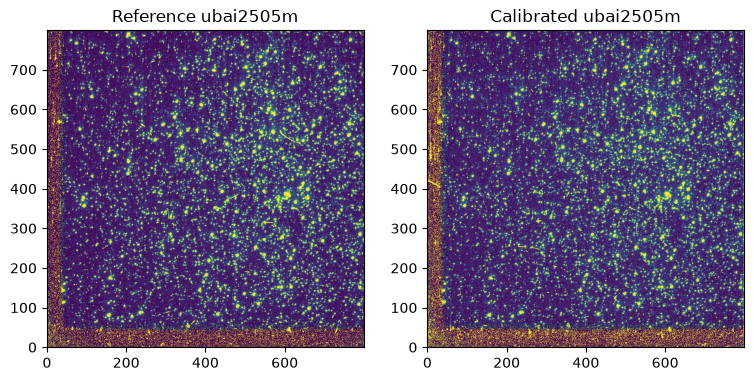

In [4]:
ubai2505m_aligned = here/'hst-data/F336W/ubai2505m_c0m_aligned.fits'
with fits.open(ubai2505m_aligned) as hdul:
            aligned2505 = hdul[1].data

plt.close('all')

pc_data = aligned2505.copy()
pc_datacal = sky_correct[0].copy()

fig, (ax, ax1) = plt.subplots(1,2,figsize=(9, 9))

ax.imshow(pc_data, origin='lower', vmin=0, vmax=5)
ax.set_title("Reference ubai2505m")

ax1.imshow(pc_datacal, origin='lower', vmin=0, vmax=5)
ax1.set_title("Calibrated ubai2505m")

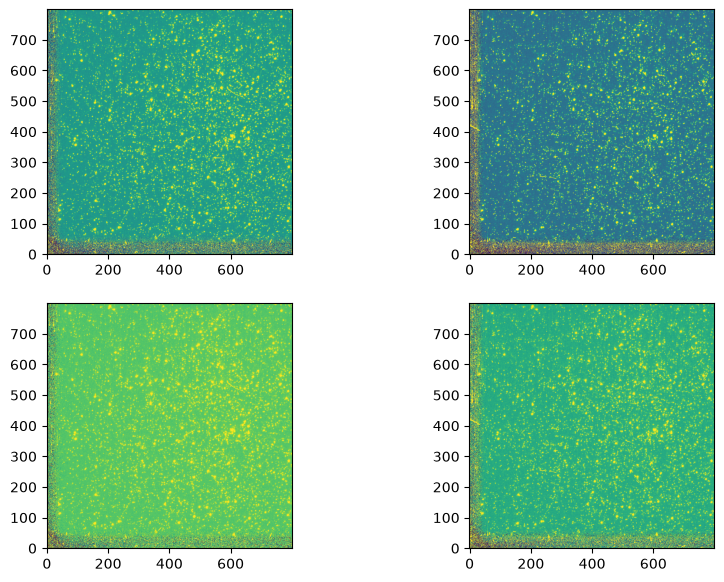

In [5]:
counts = np.nan_to_num(pc_datacal, nan=0)
pc_log = Functions.transform_by('log', pc_data, pmin=1, pmax=95)
pc_logcal = Functions.transform_by('log', counts, pmin=1, pmax=95)
fluxsqrt = Functions.transform_by('sqrt', pc_data, pmin=1, pmax=95)
fluxsqrtcal = Functions.transform_by('sqrt', counts, pmin=1, pmax=95)
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2,2, figsize=(10, 7))
ax1.imshow(pc_log, origin='lower')
ax2.imshow(pc_logcal, origin='lower')
ax3.imshow(fluxsqrt, origin='lower')
ax4.imshow(fluxsqrtcal, origin='lower')
plt.show()

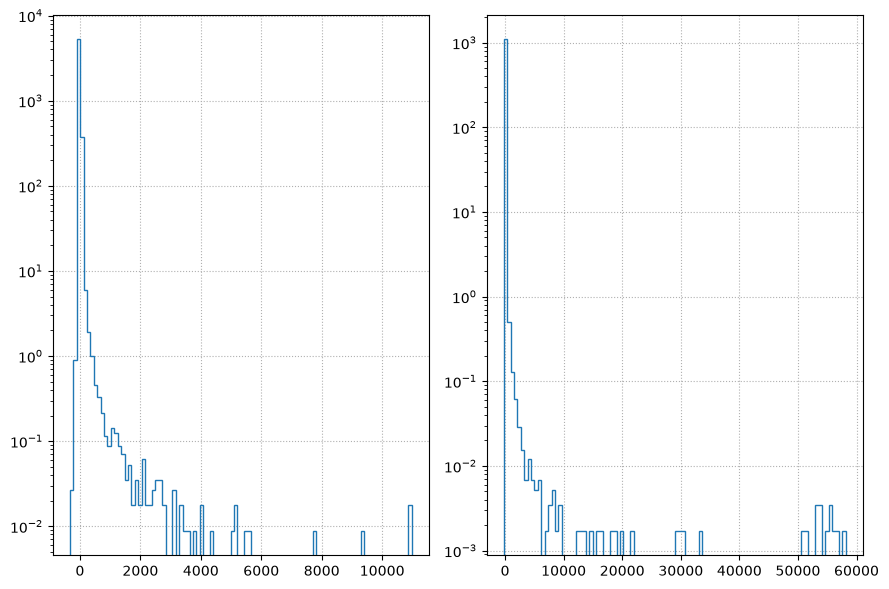

In [6]:
counts = np.nan_to_num(pc_datacal, nan=0)

fig2, (ax,ax1) = plt.subplots(1,2,figsize=(9, 6))

Functions.histogram(ax, pc_data)
Functions.histogram(ax1, counts)

ax.set_yscale('log')
ax1.set_yscale('log')

ax.grid(ls=':')
ax1.grid(ls=':')

plt.tight_layout()

In [7]:
#Convert to flux
aligned = Functions.flux(time, PHOTOFLAM,aligned2505)
maskp = ~np.isnan(sky_correct[0])
Cal = Functions.flux(time, PHOTOFLAM, sky_correct[0][maskp])

ma= aligned.mean()
mc =Cal.mean()

photo = [ma, mc]

mag = Functions.magnitude(photo, PHOTOFLAM)

print(f"The mean flux of the reference data is {ma}, and of the calibrated data is {mc}")
print(f"Flux {ma} magnitude is {mag[0]}")
print(f"Flux {mc} magnitude is {mag[1]}")

The mean flux of the reference data is 4.2933338864038206e-19, and of the calibrated data is 8.269164883540667e-19
Flux 4.2933338864038206e-19 magnitude is 105.73013301514504
Flux 8.269164883540667e-19 magnitude is 104.09145811096064


In [8]:
from scipy.ndimage import gaussian_filter, convolve
filtered_image = gaussian_filter(Cal , sigma=1, mode='reflect')

filtered_image.min(), filtered_image.max()
def get_local_max(data, nsize=10):
    """ apply a maximum filter to extract coordinates """
    local_max = maximum_filter(data, size=nsize)
    local_max_mask = (local_max == data)
    coordinates = np.argwhere(local_max_mask)
    print(f"The maximum_filter found {len(coordinates)} possible sources")
    return coordinates

coords1 = get_local_max(aligned2505)
coords2 = get_local_max(sky_correct[0])

The maximum_filter found 4896 possible sources
The maximum_filter found 4993 possible sources


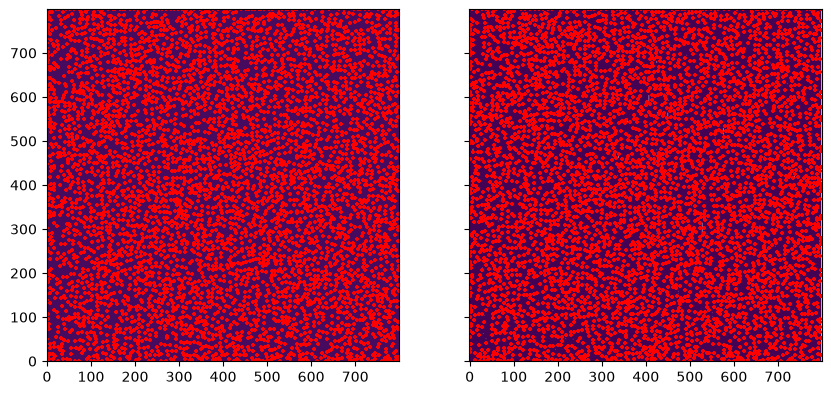

In [9]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)
# sqrt_filtered = cutils.transform_by('sqrt', filtered_image, pmin=1, pmax=99)
ax1.imshow(aligned2505, origin='lower')
ax2.imshow(sky_correct[0], origin='lower')
ax1.scatter(coords1[:, 1], coords1[:, 0], s=10, marker='+', c='r', label='basic max filter')
ax2.scatter(coords2[:, 1], coords2[:, 0], s=10, marker='+', c='r', label='gaussian filtered max filter')
plt.show()

In [10]:
test_coords = [[700, 350], [470, 369], [150, 550] ]
aligngauss = []
for val in test_coords:
    
    p0al = [
        aligned.max(), # amplitude
        val[1], # x center
        val[0], # y center
        0.5, # sigx
        0.5 # sigy
    ]
    yvalsal, xvalsal = np.indices(aligned.shape)
    poptal, pcoval = curve_fit(
        Functions.gauss_2d,
        (yvalsal, xvalsal),
        aligned.ravel(),
        p0=p0al
    )
    aligngauss.append(poptal)
   
calibrgauss = []
for val in test_coords:
    Calflux = Functions.flux(time, PHOTOFLAM, counts)
    p0cal = [
        Calflux.max(), # amplitude
        val[1], # x center
        val[0], # y center
        0.5, # sigx
        0.5 # sigy
    ]
    yvalscal, xvalscal = np.indices(Calflux.shape)
    poptcal, pcovcal = curve_fit(
        Functions.gauss_2d,
        (yvalscal, xvalscal),
        Calflux.ravel(),
        p0=p0cal
    )
    calibrgauss.append(poptcal)
print(f"For reference: \nFirst coords:{aligngauss[0]},\nSecond coords:{aligngauss[1]}, \nThird coords:{aligngauss[2]} ")
print(f"For calibrated: \nFirst coords:{calibrgauss[0]},\nSecond coords:{calibrgauss[1]},\nThird coords:{calibrgauss[2]}")

For reference: 
First coords:[5.73352388e-17 3.48137420e+02 7.03483060e+02 9.26169123e-01
 8.60385782e-01],
Second coords:[6.28219259e-17 3.68681245e+02 4.70338150e+02 7.95574653e-01
 8.05170177e-01], 
Third coords:[3.59155388e-18 5.51991721e+02 1.47661306e+02 1.27075012e+00
 8.67812983e-01] 
For calibrated: 
First coords:[4.91483596e-17 3.48150637e+02 7.03665805e+02 9.22660243e-01
 8.37367952e-01],
Second coords:[4.99721788e-17 3.68678827e+02 4.70558093e+02 8.20946505e-01
 8.38569994e-01],
Third coords:[8.36188962e-19 5.49691608e+02 1.51380444e+02 1.06861053e+00
 1.47228724e+00]


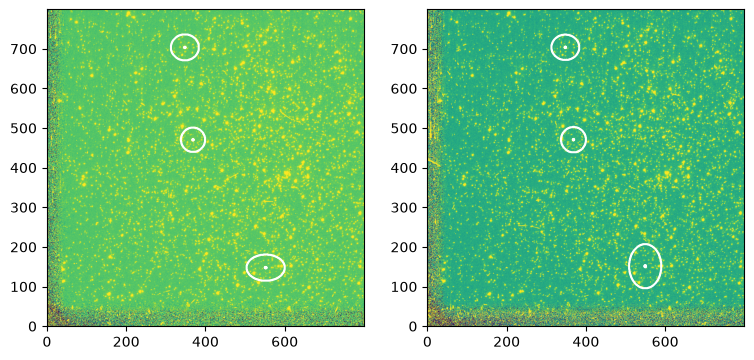

In [11]:
plt.close('all')
fig, (ax,ax1) = plt.subplots(1,2,figsize=(9, 9))

ax.imshow(fluxsqrt, origin='lower')
ax1.imshow(fluxsqrtcal, origin='lower')


for list in aligngauss:
    fitted_gaussian = Functions.gauss_2d(
        (yvalsal, xvalsal),
        *list
    ).reshape(aligned2505.shape)
    
    ax.contour(xvalsal, yvalsal, fitted_gaussian, levels=5, colors='white', vmin=0, vmax=5)

for list in calibrgauss:   
    fitted_gaussian2 = Functions.gauss_2d(
        (yvalscal, xvalscal),
        *list
    ).reshape(sky_correct[0].shape)


    ax1.contour(xvalscal, yvalscal, fitted_gaussian2, levels=5, colors='white', vmin=0, vmax=5)
plt.show()

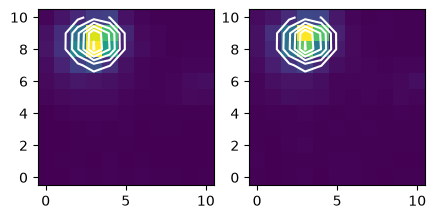

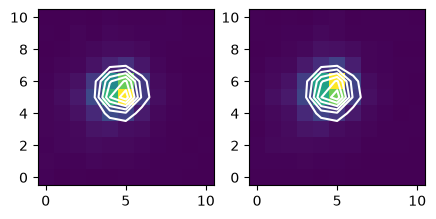

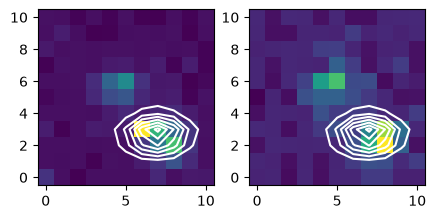

In [12]:
plt.close('all')

for val in test_coords:
    cutout = Functions.square_aperture(aligned, center=val, box_size=10)
    popt, pcov = Functions.fit_gauss_2d(cutout)

    cutout1 = Functions.square_aperture(Calflux, center=val, box_size=10)
    popt1, pcov1 = Functions.fit_gauss_2d(cutout)
    
    fig, (ax,ax1) = plt.subplots(1,2,figsize=(5,5))
    ax.imshow(cutout, origin='lower')
    ax1.imshow(cutout1, origin='lower')
    
    yind, xind = np.indices(cutout.shape)
    fitted = Functions.gauss_2d([yind, xind], *popt).reshape(cutout.shape)
    yind1, xind1 = np.indices(cutout.shape)
    fitted1 = Functions.gauss_2d([yind1, xind1], *popt1).reshape(cutout1.shape)

    ax.contour(xind, yind, fitted, levels=7, colors='white')
    ax1.contour(xind1, yind1, fitted1, levels=7, colors='white')
    plt.show()
  